# 03 - Transformer: Decoder-only

In [3]:
from pixelgen.data.dataset import ShapesDataset
from pixelgen.data.tokenizer import TextTokenizer

In [2]:
import json
from pathlib import Path
import numpy as np

root = Path("../data/processed/shapes_v1")
manifest = json.loads((root / "manifest.json").read_text())
splits = ["train", "val", "test_iid", "test_comp"]
data = {s: np.load(root / f"{s}.npz") for s in splits}

print(manifest["counts"])
d = data["train"]
for k in d.files:
    print(f"{k:10s} {d[k].shape}  {d[k].dtype}")
print(d["captions"][:3])

{'train': 200000, 'val': 5000, 'test_iid': 5000, 'test_comp': 10000}
images     (200000, 16, 16)  uint8
n_obj      (200000,)  uint8
color      (200000, 2)  int8
shape      (200000, 2)  int8
size       (200000, 2)  int8
pos        (200000,)  int8
rel        (200000,)  int8
jitter     (200000, 2, 2)  int8
captions   (200000,)  <U56
['a large cyan triangle above a small white square'
 'a small orange cross right of a small orange square'
 'a large white cross above a small cyan circle']


In [4]:
tok = TextTokenizer(manifest["text_vocab"])
max_len = max(len(c.split()) for s in splits for c in data[s]["captions"])   # 10
n_colors = len(manifest["palette_rgb"])                                       # 9

sd = ShapesDataset(root / "train.npz", tok, max_len, n_colors)
item = sd[0]
print({k: (v.shape, v.dtype) for k, v in item.items()})
print(item["tgt_in"][:5], item["tgt_out"][:5])

{'src': (torch.Size([10]), torch.int64), 'src_pad_mask': (torch.Size([10]), torch.bool), 'tgt_in': (torch.Size([256]), torch.int64), 'tgt_out': (torch.Size([256]), torch.int64)}
tensor([9, 0, 0, 0, 0]) tensor([0, 0, 0, 0, 0])


In [17]:
len(sd)

200000

In [7]:
tok.decode(item["src"].tolist())

'a large cyan triangle above a small white square'

In [11]:
import torch

max_len = 10
SEP = 29
OFFSET = 30

seq = torch.cat([item["src"], torch.tensor([SEP]), item["tgt_out"] + OFFSET])  # (267,)
x = seq[:-1]              # entrada del modelo, (266,)
y = seq[1:].clone()       # objetivo: el siguiente token, (266,)
y[:max_len] = -100        # no se evalúa la predicción del texto ni del SEP

In [13]:
item

{'src': tensor([ 2, 14, 11, 26,  3,  2, 22, 27, 23,  0]),
 'src_pad_mask': tensor([False, False, False, False, False, False, False, False, False,  True]),
 'tgt_in': tensor([9, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 8, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 8, 8, 8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 8,
         8, 8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 8, 8, 8, 8, 8, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 8, 8, 8, 8, 8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 8, 8, 8,
         8, 8, 8, 8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 7, 7, 7, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 7, 7, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         7, 7, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0

In [12]:
seq

tensor([ 2, 14, 11, 26,  3,  2, 22, 27, 23,  0, 29, 30, 30, 30, 30, 30, 30, 30,
        30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 38, 30,
        30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 38, 30, 30, 30,
        30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 38, 38, 38, 30, 30, 30, 30,
        30, 30, 30, 30, 30, 30, 30, 30, 30, 38, 38, 38, 30, 30, 30, 30, 30, 30,
        30, 30, 30, 30, 30, 30, 38, 38, 38, 38, 38, 30, 30, 30, 30, 30, 30, 30,
        30, 30, 30, 30, 38, 38, 38, 38, 38, 30, 30, 30, 30, 30, 30, 30, 30, 30,
        30, 38, 38, 38, 38, 38, 38, 38, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30,
        30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30,
        30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30,
        30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 37, 37, 37, 30,
        30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 37, 37, 37, 30, 30, 30,
        30, 30, 30, 30, 30, 30, 30, 30, 

In [15]:
x, y

(tensor([ 2, 14, 11, 26,  3,  2, 22, 27, 23,  0, 29, 30, 30, 30, 30, 30, 30, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 38, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 38, 30, 30, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 38, 38, 38, 30, 30, 30, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 38, 38, 38, 30, 30, 30, 30, 30, 30,
         30, 30, 30, 30, 30, 30, 38, 38, 38, 38, 38, 30, 30, 30, 30, 30, 30, 30,
         30, 30, 30, 30, 38, 38, 38, 38, 38, 30, 30, 30, 30, 30, 30, 30, 30, 30,
         30, 38, 38, 38, 38, 38, 38, 38, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 37, 37, 37, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 37, 37, 37, 30, 30, 30,
         30, 30, 30, 30, 30,

In [24]:
from torch.utils.data import Dataset

class DecoderOnlyDataset(Dataset):
    def __init__(self, base, text_vocab_size, max_len):
        # base: un ShapesDataset
        # guarda base, SEP y OFFSET (calcúlalos a partir de text_vocab_size)
        n_colors = base.bos_id
        self.base = base
        self.max_len = max_len
        self.sep_id = text_vocab_size
        self.offset = text_vocab_size + 1
        self.vocab_size =  text_vocab_size + 1 + n_colors

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        item = self.base[i]
        # arma seq, x e y como en el fragmento
        seq = torch.cat(
            [item["src"], torch.tensor([self.sep_id]), item["tgt_out"] + self.offset]
        )
        x = seq[:-1].clone()
        y = seq[1:].clone()
        y[:self.max_len] = -100
        return {"x": x, "y": y}

In [25]:
dod = DecoderOnlyDataset(
    ShapesDataset(root / "train.npz", tok, max_len, n_colors),
    29,
    10
)
dod[0]

{'x': tensor([ 2, 14, 11, 26,  3,  2, 22, 27, 23,  0, 29, 30, 30, 30, 30, 30, 30, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 38, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 38, 30, 30, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 38, 38, 38, 30, 30, 30, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 38, 38, 38, 30, 30, 30, 30, 30, 30,
         30, 30, 30, 30, 30, 30, 38, 38, 38, 38, 38, 30, 30, 30, 30, 30, 30, 30,
         30, 30, 30, 30, 38, 38, 38, 38, 38, 30, 30, 30, 30, 30, 30, 30, 30, 30,
         30, 38, 38, 38, 38, 38, 38, 38, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 37, 37, 37, 30,
         30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 30, 37, 37, 37, 30, 30, 30,
         30, 30, 30, 30

In [26]:
dds = DecoderOnlyDataset(sd, tok.vocab_size, max_len)
item = dds[0]
print(item["x"].shape, item["y"].shape)     # (266,) y (266,)
print((item["x"] >= 0).all())               # True
print(item["y"][:12])                       # diez -100 y luego dos valores más
print(dds.vocab_size)                       # 39

torch.Size([266]) torch.Size([266])
tensor(True)
tensor([-100, -100, -100, -100, -100, -100, -100, -100, -100, -100,   30,   30])
39


## Decoder

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F


class Head(nn.Module):
    """Una cabeza de self-attention."""

    def __init__(self, n_embd, head_size, block_size, dropout):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)                                                   # (B, T, hs)
        q = self.query(x)                                                 # (B, T, hs)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5               # (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)                                                 # (B, T, hs)
        return wei @ v  

In [ ]:
class MultiHeadAttention(nn.Module):
    """Varias cabezas de self-attention en paralelo."""

    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        assert n_embd % n_head == 0, "n_embd must be divisible by n_head"
        head_size = n_embd // n_head
        self.heads = nn.ModuleList(
            [Head(n_embd, head_size, block_size, dropout) for _ in range(n_head)]
        )
        self.proj = nn.Linear(head_size * n_head, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))

In [ ]:

class FeedFoward(nn.Module):
    """Capa lineal → ReLU → capa lineal."""

    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    """Bloque Transformer: comunicación (atención) seguida de cómputo (feedforward)."""

    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_embd, n_head, block_size, dropout)
        self.ffwd = FeedFoward(n_embd, dropout)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class GPTLanguageModel(nn.Module):

    def __init__(self, vocab_size, n_embd, n_head, n_layer, block_size, dropout):
        super().__init__()
        self.block_size = block_size
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(
            *[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)]
        )
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)                                    # (B, T, C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=idx.device))  # (T, C)
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)                                                     # (B, T, vocab)

        if targets is None:
            return logits, None
        B, T, C = logits.shape
        loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

    



In [27]:
import math
import torch
from torch.utils.data import DataLoader

from pixelgen.data.dataset_gpt import DecoderOnlyDataset
from pixelgen.models.decoder_only import DecoderOnlyTransformer

# 1) Dataset y un lote de 8 ejemplos
dds = DecoderOnlyDataset(sd, tok.vocab_size, max_len)    # sd es tu ShapesDataset de train
loader = DataLoader(dds, batch_size=8, shuffle=True)
batch = next(iter(loader))
x, y = batch["x"], batch["y"]
print(x.shape, y.shape)            # (8, 266) y (8, 266)

# 2) Modelo pequeño
model = DecoderOnlyTransformer(
    vocab_size=dds.vocab_size,     # 39
    n_embd=128,
    n_head=4,
    n_layer=4,
    block_size=x.shape[1],         # 266, tomado del propio lote
    dropout=0.0,
)

# 3) Una pasada
logits, loss = model(x, y)
print(logits.shape)                # (8, 266, 39)
print(loss.item(), math.log(dds.vocab_size))   # ambos deberían rondar 3.66

torch.Size([8, 266]) torch.Size([8, 266])
torch.Size([8, 266, 39])
3.651172161102295 3.6635616461296463


In [28]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
model.train()

for step in range(200):
    logits, loss = model(x, y)
    optimizer.zero_grad(set_to_none=True)   # 1) borra los gradientes del paso anterior
    loss.backward()                         # 2) calcula los gradientes de la pérdida
    optimizer.step()                        # 3) actualiza los pesos
    if step % 20 == 0:
        print(step, loss.item())

0 3.651172161102295
20 0.731185257434845
40 0.5094684362411499
60 0.3543599545955658
80 0.18302743136882782
100 0.0872792899608612
120 0.027912940829992294
140 0.014492501504719257
160 0.00470297085121274
180 0.0033538478892296553


In [31]:
@torch.no_grad()
def evaluate(model, loader, max_batches=20):
    """Mean loss over up to ``max_batches`` batches, with dropout off and no gradients."""
    model.eval()
    losses = []
    for i, batch in enumerate(loader):
        if i >= max_batches:
            break
        _, loss = model(batch["x"], batch["y"])
        losses.append(loss.item())
    model.train()
    return sum(losses) / len(losses)

n_colors = len(manifest["palette_rgb"])

train_base = ShapesDataset(root / "train.npz", tok, max_len, n_colors)
val_base = ShapesDataset(root / "val.npz", tok, max_len, n_colors)

train_ds = DecoderOnlyDataset(train_base, tok.vocab_size, max_len)
val_ds = DecoderOnlyDataset(val_base, tok.vocab_size, max_len)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

model_nuevo = DecoderOnlyTransformer(
    vocab_size=train_ds.vocab_size,
    n_embd=128,
    n_head=4,
    n_layer=4,
    block_size=266,
    dropout=0.0,
)

print(evaluate(model_nuevo, val_loader))     # debería rondar 3.65   # debería rondar 3.65

4.000464022159576


In [32]:
for seed in range(5):
    torch.manual_seed(seed)
    m = DecoderOnlyTransformer(vocab_size=train_ds.vocab_size, n_embd=128, n_head=4,
                               n_layer=4, block_size=266, dropout=0.0)
    print(seed, evaluate(m, val_loader))

0 3.6414732098579408
1 3.4880558490753173
2 3.5957175970077513
3 3.644683504104614
4 3.59227569103241


In [40]:
import time

@torch.no_grad()
def evaluate(model, loader, device, max_batches=20):
    model.eval()
    losses = []
    for i, batch in enumerate(loader):
        if i >= max_batches:
            break
        x, y = batch["x"].to(device), batch["y"].to(device)
        _, loss = model(x, y)
        losses.append(loss.item())
    model.train()
    return sum(losses) / len(losses)

tok = TextTokenizer(manifest["text_vocab"])
max_len = max(len(c.split()) for s in splits for c in data[s]["captions"])   # 10
n_colors = len(manifest["palette_rgb"])    

train_base = ShapesDataset(root / "train.npz", tok, max_len, n_colors)
val_base = ShapesDataset(root / "val.npz", tok, max_len, n_colors)

train_ds = DecoderOnlyDataset(train_base, tok.vocab_size, max_len)
val_ds = DecoderOnlyDataset(val_base, tok.vocab_size, max_len)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

device = "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(0)
model = DecoderOnlyTransformer(
    vocab_size=train_ds.vocab_size, n_embd=128, n_head=4,
    n_layer=4, block_size=266, dropout=0.0,
).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

max_steps = 5000
eval_every = 100
step = 0
start = time.time()

while step < max_steps:
    for batch in train_loader:
        x, y = batch["x"].to(device), batch["y"].to(device)

        _, loss = model(x, y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if step % eval_every == 0:
            val_loss = evaluate(model, val_loader, device)
            print(f"step {step:4d} | train {loss.item():.4f} | val {val_loss:.4f}"
                  f" | {time.time() - start:.0f}s")

        step += 1
        if step >= max_steps:
            break

print(f"done in {time.time() - start:.0f}s")

step    0 | train 3.6320 | val 2.4571 | 1s
step  100 | train 0.3945 | val 0.3950 | 8s
step  200 | train 0.2345 | val 0.2358 | 16s
step  300 | train 0.1620 | val 0.1656 | 24s
step  400 | train 0.1329 | val 0.1325 | 32s
step  500 | train 0.1094 | val 0.1143 | 40s
step  600 | train 0.1068 | val 0.1004 | 48s
step  700 | train 0.0826 | val 0.0876 | 55s
step  800 | train 0.0760 | val 0.0763 | 63s
step  900 | train 0.0672 | val 0.0637 | 72s
step 1000 | train 0.0599 | val 0.0641 | 80s
step 1100 | train 0.0498 | val 0.0506 | 89s
step 1200 | train 0.0447 | val 0.0446 | 98s
step 1300 | train 0.0370 | val 0.0411 | 106s
step 1400 | train 0.0364 | val 0.0370 | 115s
step 1500 | train 0.0350 | val 0.0334 | 123s
step 1600 | train 0.0290 | val 0.0330 | 132s
step 1700 | train 0.0306 | val 0.0291 | 141s
step 1800 | train 0.0272 | val 0.0282 | 149s
step 1900 | train 0.0245 | val 0.0272 | 158s
step 2000 | train 0.0252 | val 0.0256 | 166s
step 2100 | train 0.0246 | val 0.0247 | 175s
step 2200 | train 0.0243 

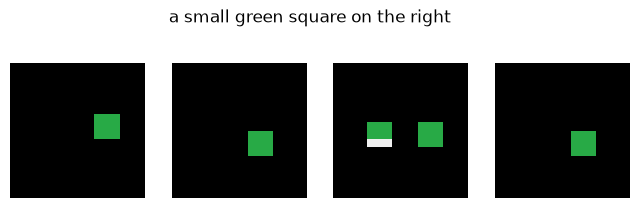

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F


@torch.no_grad()
def generate_image(model, caption, tok, dds, device, temperature=1.0, n_pixels=256):
    """Sample a 16x16 image of palette indices for a caption, one pixel at a time."""
    was_training = model.training
    model.eval()

    # Prefix: caption padded to max_len, then the separator.
    ids = tok.encode(caption, dds.max_len) + [dds.sep_id]
    seq = torch.tensor([ids], dtype=torch.long, device=device)  # (1, max_len + 1)

    # Only palette colors may be generated: ids offset .. offset + n_colors - 1.
    n_colors = dds.base.bos_id
    lo, hi = dds.offset, dds.offset + n_colors

    for _ in range(n_pixels):
        logits, _ = model(seq)  # (1, T, vocab)
        logits = logits[:, -1, lo:hi] / temperature  # last position, colors only
        probs = F.softmax(logits, dim=-1)
        nxt = torch.multinomial(probs, num_samples=1) + lo  # back to global ids
        seq = torch.cat([seq, nxt], dim=1)

    pixels = seq[0, len(ids):] - dds.offset  # drop the prefix, undo the offset
    if was_training:
        model.train()
    return pixels.reshape(16, 16).cpu().numpy()

palette = np.array(manifest["palette_rgb"], dtype=np.uint8)

caption = "a small green square on the right"
fig, axes = plt.subplots(1, 4, figsize=(8, 2.5))
for ax in axes:
    img = generate_image(model, caption, tok, train_ds, device)
    ax.imshow(palette[img], interpolation="nearest")
    ax.axis("off")
fig.suptitle(caption)
plt.show()